In [1]:
####################################################
####################################################
## test the keypoint_moseq with SLEAP output 
## original notebook from https://keypoint-moseq.readthedocs.io/en/stable/modeling.html
####################################################
####################################################

In [2]:
import keypoint_moseq as kpms
import matplotlib.pyplot as plt

In [47]:
import numpy as np

In [3]:
project_dir = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test"
#project_dir = "/Users/jingkui.wang/workspace/imp/image_analysis_test/results/videos_sleap_test"

config = lambda: kpms.load_config(project_dir)

kpms.check_installation(notebook_version="0.8")

keypoint-MoSeq installation check
  Python 3.12.16 (/Users/jingkui.wang/miniforge3/envs/keypoint_moseq/bin/python)
  keypoint-moseq   0.8.4     /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/keypoint_moseq
  jax-moseq        0.3.8     /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/jax_moseq
  jax              0.12.0.1  /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/jax
  jaxlib           0.12.0.1  /Users/jingkui.wang/miniforge3/envs/keypoint_moseq/lib/python3.12/site-packages/jaxlib
  JAX CUDA plugin  not installed
  Devices: cpu:0 (cpu)
  JAX is using the CPU. For GPU support (Linux only), install keypoint-moseq[cuda] and use a machine with a GPU.
  Notebook: written for 0.8, as installed


In [6]:
## setup for SLEAP
sleap_file = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/labels.v003_245frames.labeled_trained.slp"  # any .slp or .h5 file with predictions for a single video
kpms.setup_project(project_dir, sleap_file=sleap_file)

The directory `/Volumes/groups/tanaka/People/current/jiwang/projects/i
mage_analysis/Deniz_video_sleap/sleap_test/kpms_test` already exists.
Use `overwrite=True` or pick a different name


In [7]:
## Edit the config file
kpms.update_config(
    project_dir,
    video_dir="/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/",
    anterior_bodyparts=["nose"],
    posterior_bodyparts=["tail_tip"],
    use_bodyparts=["nose", "eyeL", "eyeR", "head", "torso", "tail_base", "tail_2", "tail_3", "tail_tip"],
    fps=30,
)

In [8]:
# load data (e.g. from SLEAP)
keypoint_data_path = "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/labels.v003_245frames.labeled_trained.slp"  # can be a file, a directory, or a list of files
coordinates, confidences, bodyparts = kpms.load_keypoints(keypoint_data_path, "sleap")

Loading keypoints: 100%|██████████████████| 1/1 [00:01<00:00,  1.67s/it]


In [9]:
#video_paths = {
#    "labels.v003_245frames.labeled_trained": (
#        "/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/EXP009_A2-IR_260910_6x.mp4"
#    )
#}
#check_config = config().copy()
#check_config["video_paths"] = video_paths

In [10]:
coordinates
confidences
bodyparts

['nose',
 'eyeL',
 'eyeR',
 'head',
 'torso',
 'tail_base',
 'tail_2',
 'tail_3',
 'tail_tip']

In [11]:
## check videos
kpms.check_videos(coordinates, print_table=True, **config())

Checking videos: 100%|████████████████████| 1/1 [00:00<00:00, 24.82it/s]

Videos matched to 1 of 1 recordings:
  labels.v003_245frames.labeled_trained
    /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4  (3,784 frames, 600 x 600)


{'labels.v003_245frames.labeled_trained': '/Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/videos/labels.v003_245frames.labeled_trained.mp4'}

In [12]:
data, metadata = kpms.format_data(coordinates, confidences, **config())

Loading sample frames: 100%|███████████| 40/40 [00:00<00:00, 204.59it/s]


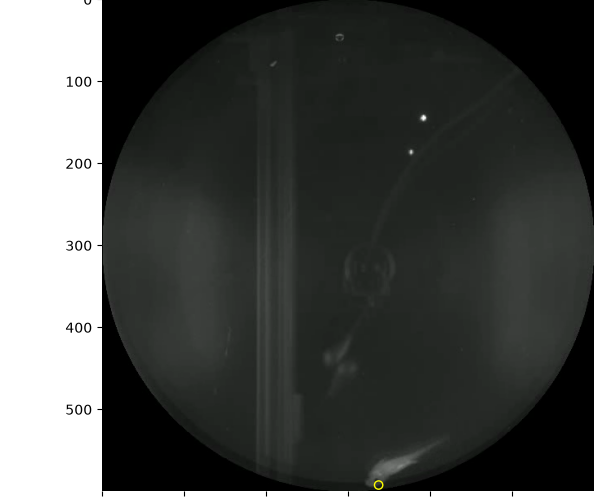

In [13]:
%matplotlib widget
kpms.noise_calibration(project_dir, coordinates, confidences, **config())

>=90.0% of variance explained by 3 components.


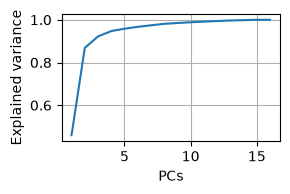

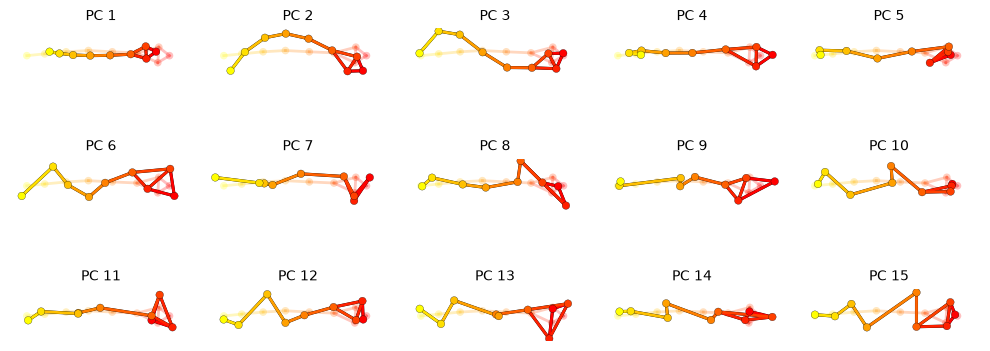

In [116]:
plt.close("all")
%matplotlib inline
pca = kpms.fit_pca(**data, **config())
kpms.save_pca(pca, project_dir)

kpms.print_dims_to_explain_variance(pca, 0.9)
kpms.plot_scree(pca, project_dir=project_dir)
kpms.plot_pcs(pca, project_dir=project_dir, plot_n_pcs=15, **config())

# use the following to load an already fit model
# pca = kpms.load_pca(project_dir)


In [117]:
kpms.update_config(project_dir, latent_dim=10)

In [118]:
## Estimating Hyperparameters
kpms.update_config(
    project_dir,
    sigmasq_loc=kpms.estimate_sigmasq_loc(data["Y"], data["mask"], filter_size=config()["fps"])
)

In [119]:
# initialize the model
model = kpms.init_model(data, metadata=metadata, pca=pca, **config())

In [120]:
# optionally modify kappa
#model = kpms.update_hypparams(model, kappa=)

In [123]:
kappa = 10000
decrease_kappa_factor = 10
num_ar_iters = 50
num_full_iters = 200
print(kappa)

10000


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11
_04-11_49_54


 47%|████████████████▍                  | 24/51 [00:01<00:01, 14.30it/s]

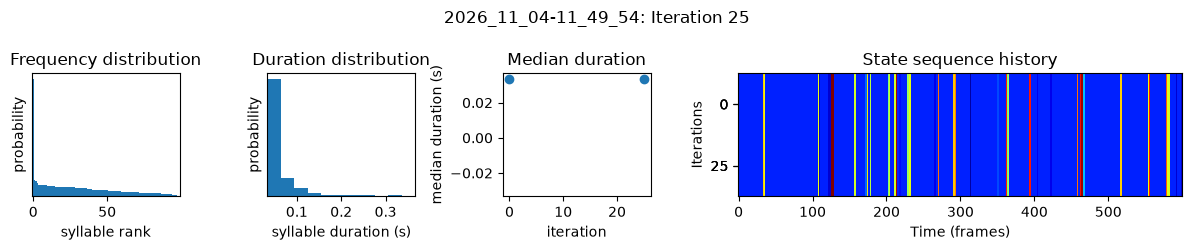

 98%|██████████████████████████████████▎| 50/51 [00:03<00:00, 14.11it/s]

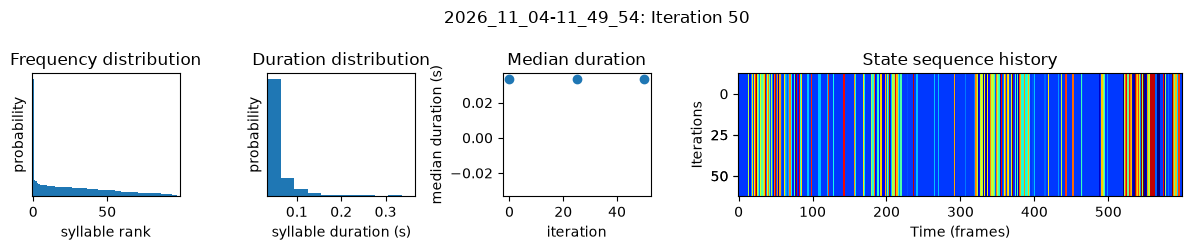

100%|███████████████████████████████████| 51/51 [00:04<00:00, 11.24it/s]
'kappa' with <class 'int'> will be cast to <class 'float'>

Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11
_04-11_49_54


 98%|██████████████████████████████████▎| 50/51 [00:03<00:00, 14.06it/s]

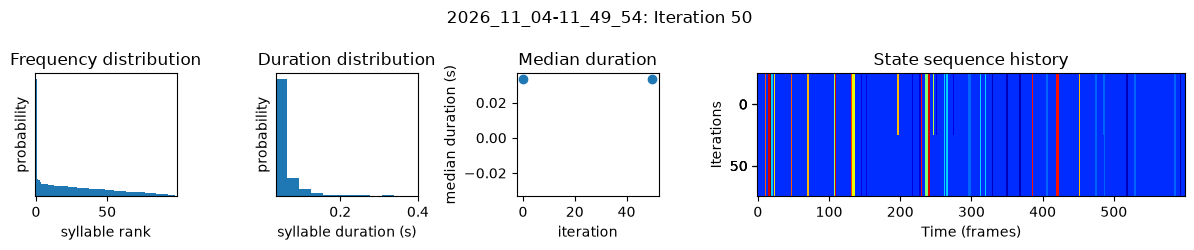

100%|███████████████████████████████████| 51/51 [00:04<00:00, 12.59it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11
_04-11_49_54


 12%|████▏                             | 25/201 [00:07<00:55,  3.19it/s]

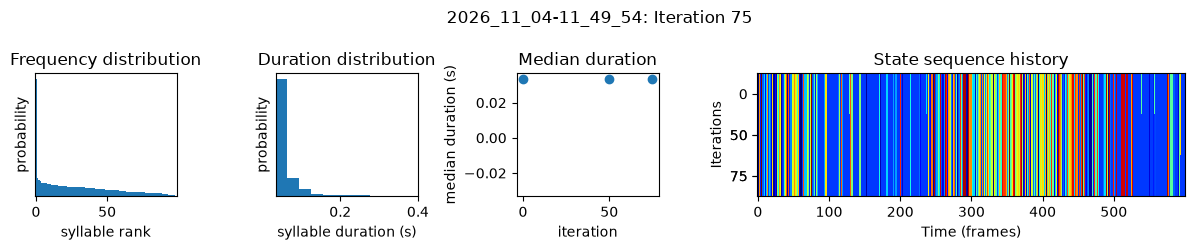

 25%|████████▍                         | 50/201 [00:16<00:47,  3.21it/s]

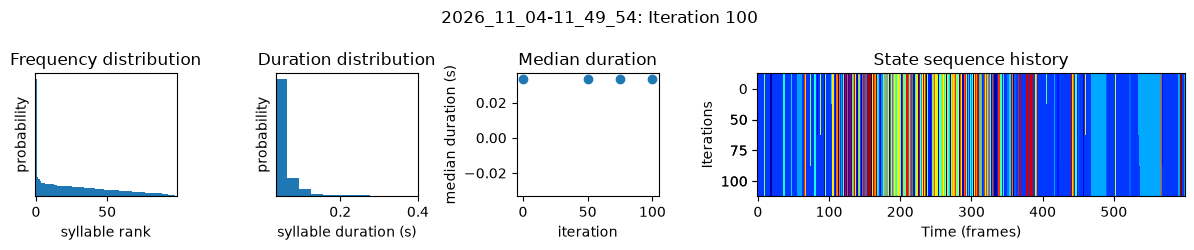

 37%|████████████▋                     | 75/201 [00:24<00:39,  3.19it/s]

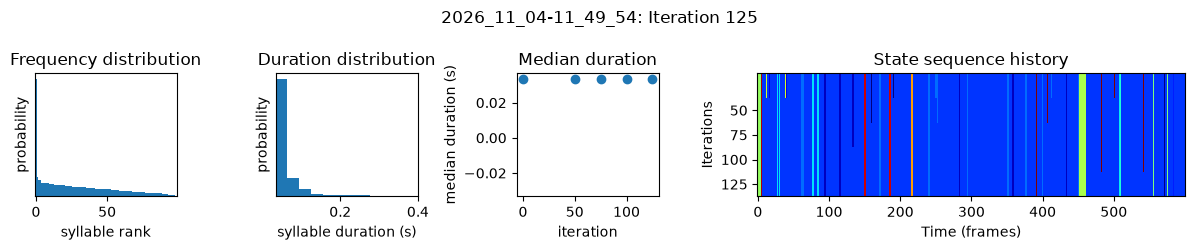

 50%|████████████████▍                | 100/201 [00:32<00:31,  3.22it/s]

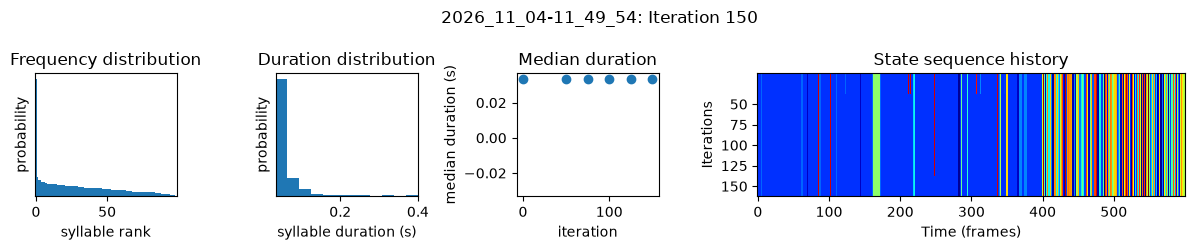

 62%|████████████████████▌            | 125/201 [00:41<00:23,  3.20it/s]

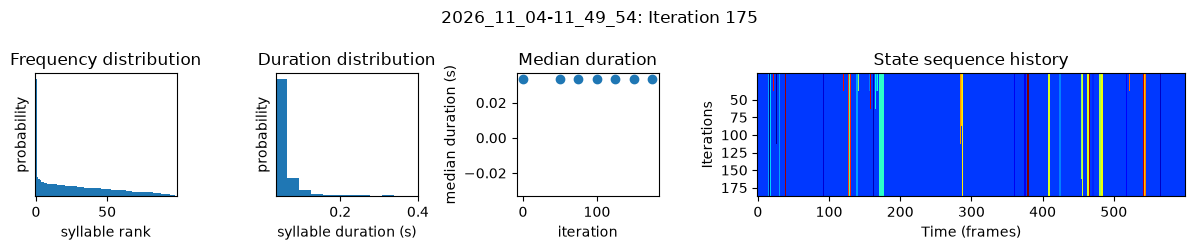

 75%|████████████████████████▋        | 150/201 [00:49<00:15,  3.21it/s]

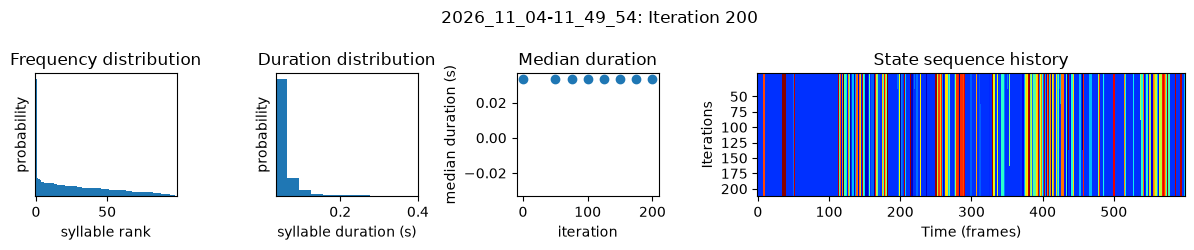

 87%|████████████████████████████▋    | 175/201 [00:58<00:08,  3.20it/s]

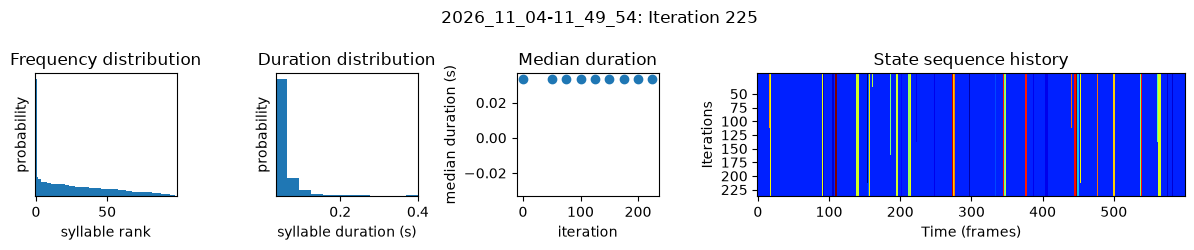

100%|████████████████████████████████▊| 200/201 [01:06<00:00,  3.15it/s]

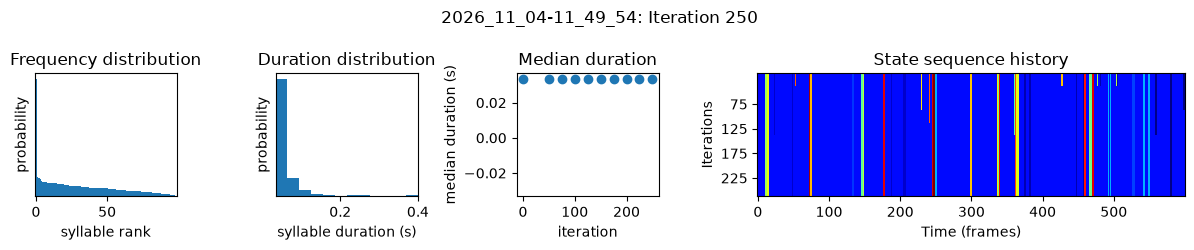

100%|█████████████████████████████████| 201/201 [01:07<00:00,  2.98it/s]


In [124]:
## Fitting an AR-HMM
model, model_name = kpms.fit_model(
    model, data, metadata, project_dir, ar_only=True, num_iters=num_ar_iters, **config()
)

## Fitting the full model
# load model checkpoint
model, data, metadata, current_iter = kpms.load_checkpoint(
    project_dir, model_name, iteration=num_ar_iters
)

# modify kappa to maintain the desired syllable time-scale
#model = kpms.update_hypparams(model, kappa=1e2)
model = kpms.update_hypparams(model, kappa=kappa)
model = kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=True,
        num_iters=num_ar_iters,
        save_every_n_iters=50,
        **config()
    )[0];

# stage 2: fit the full model
model = kpms.update_hypparams(model, kappa=kappa/decrease_kappa_factor)

# run fitting for an additional 500 iters
model = kpms.fit_model(
    model,
    data,
    metadata,
    project_dir,
    model_name,
    ar_only=False,
    start_iter=current_iter,
    num_iters=current_iter + num_full_iters,
    **config(),
)[0]

In [125]:
## Sort syllables by frequency
# modify a saved checkpoint so syllables are ordered by frequency
kpms.reindex_syllables_in_checkpoint(project_dir, model_name);

Reindexing: 100%|███████████| 10/10 [00:01<00:00,  6.97model snapshot/s]


In [126]:
# load the most recent model checkpoint
#model, data, metadata, current_iter = kpms.load_checkpoint(project_dir, model_name)

# extract results
results = kpms.extract_results(model, metadata, project_dir, model_name, overwrite=True)

Saved results to /Volumes/groups/tanaka/People/current/jiwang/projects
/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-
11_49_54/results.h5


In [127]:
# optionally save results as csv
kpms.save_results_as_csv(results, project_dir, model_name)

Saving to csv: 100%|██████████████████████| 1/1 [00:00<00:00,  4.07it/s]


In [128]:
results = kpms.load_results(project_dir, model_name)


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Frequency distribution'}, xlabel='syllable rank', ylabel='probability'>)

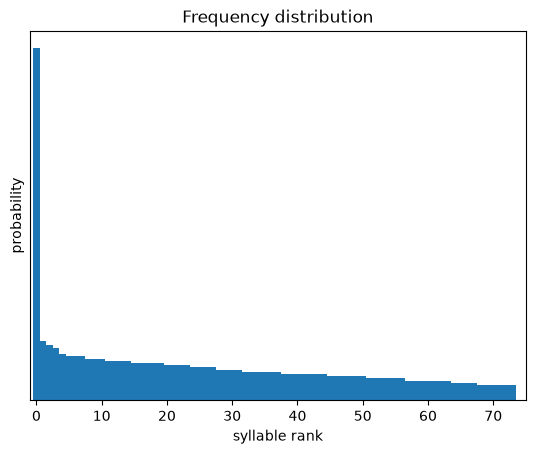

In [129]:
kpms.plot_syllable_frequencies(project_dir, model_name, results, minlength = 10, min_frequency = 0.005)

In [130]:
#kpms.plot_duration_distribution(project_dir, model_name, results, num_bins = 50)

In [131]:
coordinates
results
#project_dir
#model_name

{'labels.v003_245frames.labeled_trained': {'centroid': array([[247.00496971, 166.4287291 ],
         [246.93140487, 167.30247811],
         [246.81277209, 168.72512901],
         ...,
         [411.52827125,  90.2382501 ],
         [411.87652302,  90.42373675],
         [412.15451598,  90.27572267]], shape=(3784, 2)),
  'heading': array([ 2.43489675,  2.4590818 ,  2.52968136, ..., -0.92793028,
         -0.92020419, -0.91228146], shape=(3784,)),
  'latent_state': array([[-0.40501485, -1.91330932, -1.36584892, ...,  0.30059123,
          -0.24462501,  6.17999925],
         [-1.46449396, -1.23271169, -1.25483279, ..., -2.93359853,
          -1.20963682, -6.10624647],
         [-0.59753112, -0.34832966, -0.21468488, ..., -0.50941633,
          -0.5050879 ,  1.27669419],
         ...,
         [ 0.05686151, -1.31914649,  0.31859659, ..., -0.39054184,
          -1.09571106,  0.43609446],
         [ 0.04739518, -1.40629542,  0.39686721, ..., -0.49262215,
          -1.23814475,  1.00708635],
 

Saving trajectory plots to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-11_49_54/trajectory_plots


Generating trajectory plots: 100%|██████| 33/33 [00:10<00:00,  3.11it/s]


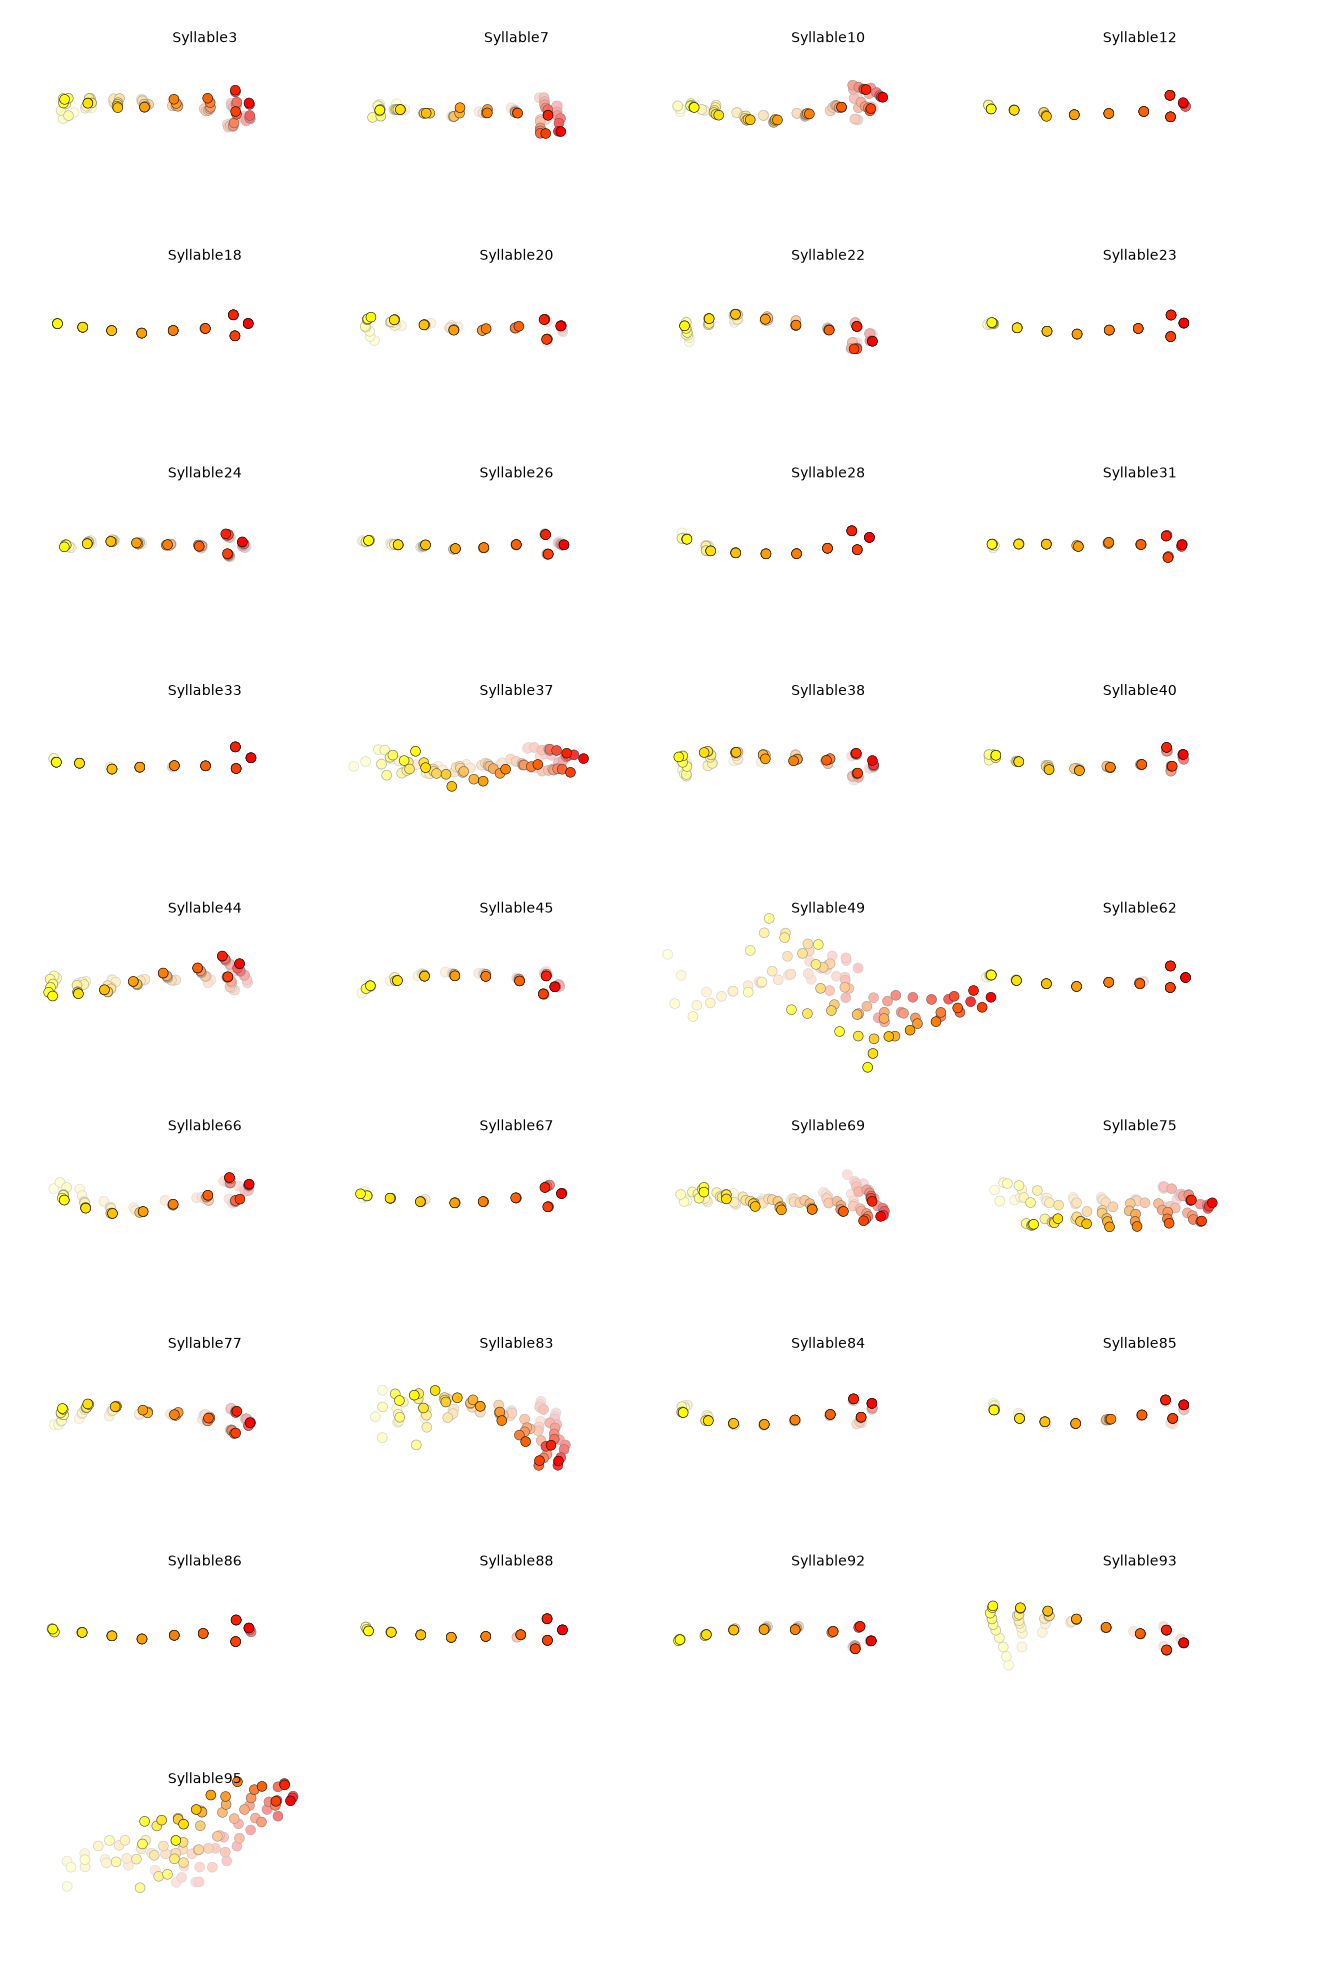

In [132]:
kpms.generate_trajectory_plots(coordinates, results, project_dir, model_name, 
                               fps = 30,
                               before_onset_frames=5, after_onset_frames=15, min_frequency=0.005, min_instance_duration_frames=5, 
                               density_sample=False,
                               #density_sample=True, sampling_options={'n_neighbors': 5},
                               #padding={'bottom': 0.2, 'left': 0.1, 'right': 0.1, 'top': 0.2},
                               )

Saving dendrogram plot to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-11_49_54/similarity_dendrogram


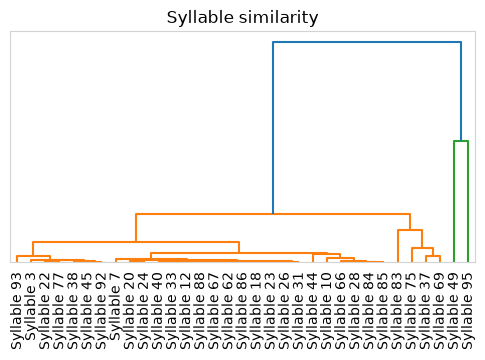

In [133]:
kpms.plot_similarity_dendrogram(coordinates, results, project_dir, model_name, **config())

In [134]:
# Define the syllables to merge as a list of lists. All syllables within
# a given inner list will be merged into a single syllable.
# In this case, we're merging syllables 1 and 3 into a single syllable,
# and merging syllables 4 and 5 into a single syllable.
syllables_to_merge = [
    [49, 95],
    [93, 3, 22, 77, 38, 45, 92],
    [44, 10, 66, 28, 84, 85],
    [83, 75, 37, 69],
    [7, 20, 24, 40, 33, 12, 88, 67, 62, 86, 18, 23, 26, 31]
]

Writing grid movies to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-11_49_54/grid_movies_merged


Checking videos: 100%|████████████████████| 1/1 [00:00<00:00, 22.23it/s]


Using window size of 160 pixels


Generating grid movies: 100%|█████████████| 1/1 [00:02<00:00,  2.85s/it]os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.


Saving trajectory plots to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-11_49_54/trajectory_plots_merged


Generating trajectory plots: 100%|████████| 1/1 [00:00<00:00,  3.15it/s]


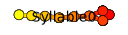

In [135]:
# Load the results you wish to merge (change path as needed)
import os
results_path = os.path.join(project_dir, model_name, 'results.h5')
results = kpms.load_hdf5(results_path)

# Generate a mapping that specifies how syllables will be relabeled.
syllable_mapping = kpms.generate_syllable_mapping(results, syllables_to_merge)
new_results = kpms.apply_syllable_mapping(results, syllable_mapping)

# Save the new results to disk (using a modified path)
new_results_path = os.path.join(project_dir, model_name, 'results_merged.h5')
kpms.save_hdf5(new_results_path, new_results)

# Optionally generate new trajectory plots and grid movies
# In each case, specify the output directory to avoid overwriting
output_dir = os.path.join(project_dir, model_name, 'grid_movies_merged')


Saving trajectory plots to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-11_49_54/trajectory_plots_merged


Generating trajectory plots: 100%|████████| 8/8 [00:02<00:00,  3.99it/s]


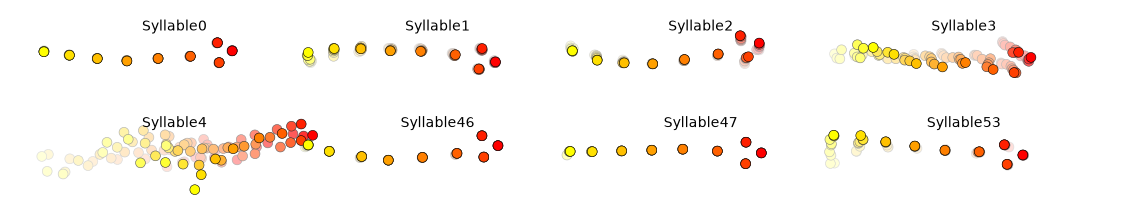

In [136]:
output_dir = os.path.join(project_dir, model_name, 'trajectory_plots_merged')
kpms.generate_trajectory_plots(coordinates, new_results, output_dir=output_dir, fps = 30,
                               before_onset_frames=5, after_onset_frames=15, min_frequency=0.005, min_instance_duration_frames=5, 
                               density_sample=False,
                              )

In [137]:
kpms.generate_grid_movies(new_results, output_dir=output_dir, coordinates=coordinates, min_instance_duration_sec = 3/30, min_frequency=0.000005, 
                          before_onset_sec=2/30, after_onset_sec=1/30, max_video_size = 100*100,
                          #num_samples= 6, mode='random', pca_samples=100, pca_dim=10, n_neighbors=5, 
                          **config())

Writing grid movies to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-11_49_54/trajectory_plots_merged


Checking videos: 100%|████████████████████| 1/1 [00:00<00:00, 40.28it/s]


Using window size of 160 pixels


Generating grid movies: 100%|█████████████| 1/1 [00:00<00:00,  2.36it/s]os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.


{np.int64(0): [('labels.v003_245frames.labeled_trained',
   np.int64(3159),
   np.int64(3168)),
  ('labels.v003_245frames.labeled_trained', np.int64(2768), np.int64(2776)),
  ('labels.v003_245frames.labeled_trained', np.int64(3221), np.int64(3228)),
  ('labels.v003_245frames.labeled_trained', np.int64(554), np.int64(566)),
  ('labels.v003_245frames.labeled_trained', np.int64(1620), np.int64(1632)),
  ('labels.v003_245frames.labeled_trained', np.int64(441), np.int64(445)),
  ('labels.v003_245frames.labeled_trained', np.int64(2653), np.int64(2700)),
  ('labels.v003_245frames.labeled_trained', np.int64(3198), np.int64(3215)),
  ('labels.v003_245frames.labeled_trained', np.int64(778), np.int64(802)),
  ('labels.v003_245frames.labeled_trained', np.int64(3522), np.int64(3536)),
  ('labels.v003_245frames.labeled_trained', np.int64(3582), np.int64(3600)),
  ('labels.v003_245frames.labeled_trained', np.int64(338), np.int64(350)),
  ('labels.v003_245frames.labeled_trained', np.int64(1123), np.in

In [142]:
indices = np.where((syllable == 49)  | (syllable == 95))[0]
indices

array([ 239,  240,  275,  276,  281,  407,  587,  600,  746, 1008, 1025,
       1044, 1062, 1138, 1157, 1724, 2882, 2883, 2937, 3008, 3273, 3279,
       3288, 3289, 3311, 3313, 3314, 3315, 3316, 3317, 3346, 3359, 3377,
       3416, 3438, 3439, 3440, 3447, 3515, 3600])

In [140]:
syllable = results['labels.v003_245frames.labeled_trained']['syllable']
values, counts = np.unique(syllable, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {value}: {count} elements")

Value 0: 9 elements
Value 1: 6 elements
Value 2: 13 elements
Value 3: 26 elements
Value 4: 12 elements
Value 5: 20 elements
Value 6: 14 elements
Value 7: 30 elements
Value 8: 17 elements
Value 9: 6 elements
Value 10: 21 elements
Value 11: 6 elements
Value 12: 16 elements
Value 13: 7 elements
Value 14: 2 elements
Value 15: 18 elements
Value 16: 10 elements
Value 17: 22 elements
Value 18: 2352 elements
Value 19: 15 elements
Value 20: 34 elements
Value 21: 2 elements
Value 22: 41 elements
Value 23: 23 elements
Value 24: 23 elements
Value 25: 17 elements
Value 26: 24 elements
Value 27: 11 elements
Value 28: 19 elements
Value 29: 58 elements
Value 31: 17 elements
Value 32: 8 elements
Value 33: 25 elements
Value 34: 7 elements
Value 35: 9 elements
Value 36: 7 elements
Value 37: 24 elements
Value 38: 16 elements
Value 39: 7 elements
Value 40: 27 elements
Value 41: 7 elements
Value 42: 10 elements
Value 43: 10 elements
Value 44: 32 elements
Value 45: 12 elements
Value 46: 3 elements
Value 47: 

In [195]:
#kpms.get_typical_trajectories(coordinates, #results, before_onset_frames=5, after_onset_frames=15, min_frequency=0.000005, min_instance_duration_frames=3, bodyparts=None, use_bodyparts=None, density_sample=True, sampling_options={'n_neighbors': 50})

In [73]:
kpms.generate_grid_movies(results, project_dir, model_name, coordinates=coordinates, min_instance_duration_sec = 3/30, min_frequency=0.000005, 
                          before_onset_sec=2/30, after_onset_sec=1/30, max_video_size = 100*100,
                          #num_samples= 6, mode='random', pca_samples=100, pca_dim=10, n_neighbors=5, 
                          **config())

Writing grid movies to /Volumes/groups/tanaka/People/current/jiwang/projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/2026_11_04-10_30_34/grid_movies


Checking videos: 100%|████████████████████| 1/1 [00:00<00:00, 36.45it/s]


Using window size of 160 pixels


Generating grid movies: 100%|█████████████| 1/1 [00:00<00:00,  2.22it/s]


{np.int64(81): [('labels.v003_245frames.labeled_trained',
   np.int64(2954),
   np.int64(2976)),
  ('labels.v003_245frames.labeled_trained', np.int64(1122), np.int64(1127)),
  ('labels.v003_245frames.labeled_trained', np.int64(3345), np.int64(3366)),
  ('labels.v003_245frames.labeled_trained', np.int64(3431), np.int64(3436)),
  ('labels.v003_245frames.labeled_trained', np.int64(402), np.int64(407)),
  ('labels.v003_245frames.labeled_trained', np.int64(3300), np.int64(3319)),
  ('labels.v003_245frames.labeled_trained', np.int64(3032), np.int64(3047)),
  ('labels.v003_245frames.labeled_trained', np.int64(3452), np.int64(3462)),
  ('labels.v003_245frames.labeled_trained', np.int64(754), np.int64(757)),
  ('labels.v003_245frames.labeled_trained', np.int64(3021), np.int64(3028)),
  ('labels.v003_245frames.labeled_trained', np.int64(275), np.int64(279)),
  ('labels.v003_245frames.labeled_trained', np.int64(719), np.int64(732)),
  ('labels.v003_245frames.labeled_trained', np.int64(3382), np.i

In [ ]:
output_dir = os.path.join(project_dir, model_name, 'trajectory_plots_merged')

In [144]:
kpms.save_results_as_csv(results, project_dir, model_name)

Saving to csv: 100%|██████████████████████| 1/1 [00:00<00:00,  4.64it/s]


In [ ]:
#kpms.grid_movie(instances, rows, cols, video_paths, centroids, headings, window_size, video_frame_indexes, dot_color=(255, 255, 255), dot_radius=4, before_onset_frames=30, after_onset_frames=60, scaled_window_size=None, edges=[], overlay_keypoints=False, coordinates=None, plot_options={}, use_dims=None)

Fitting model with kappa=1000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.39it/s]

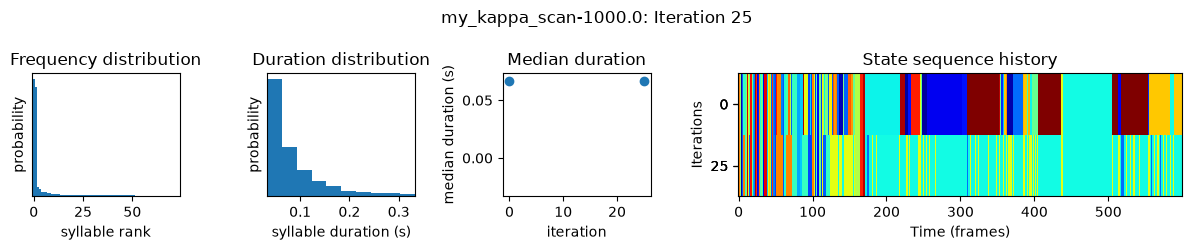

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.30it/s]

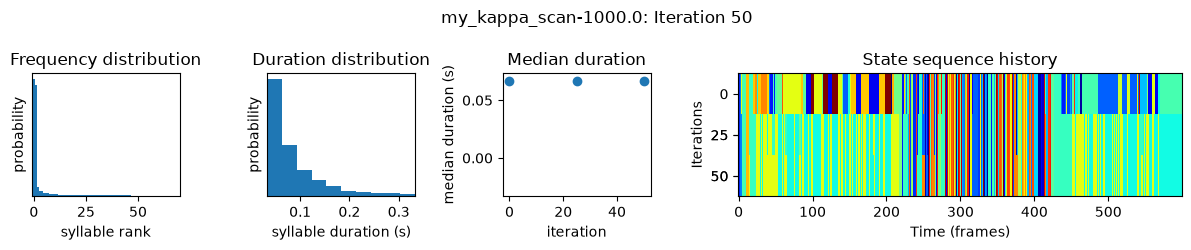

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.29it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000.0


 12%|████▏                             | 25/201 [00:04<00:29,  6.05it/s]

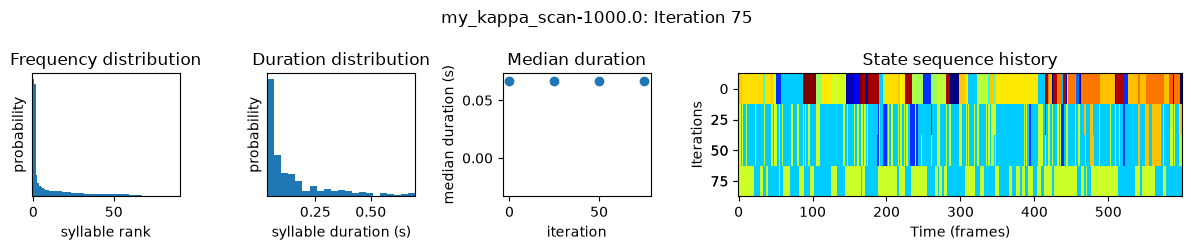

 25%|████████▍                         | 50/201 [00:08<00:25,  5.91it/s]

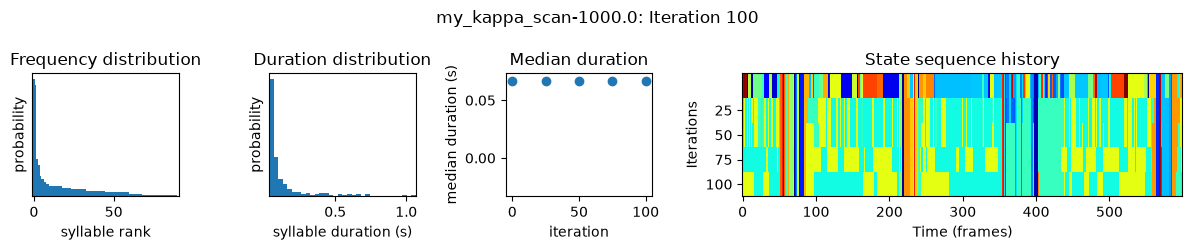

 37%|████████████▋                     | 75/201 [00:13<00:20,  6.06it/s]

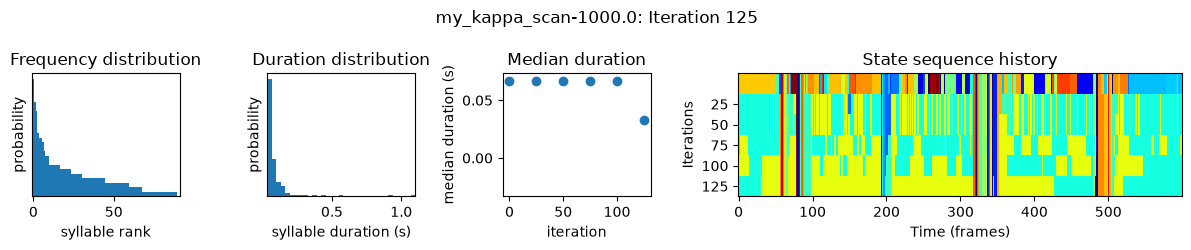

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.13it/s]

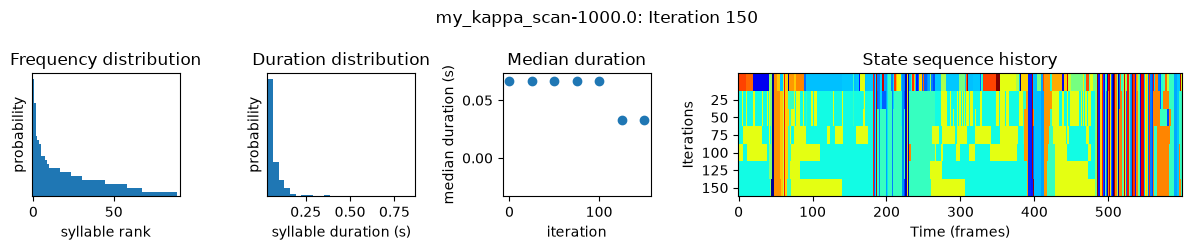

 62%|████████████████████▌            | 125/201 [00:22<00:13,  5.84it/s]

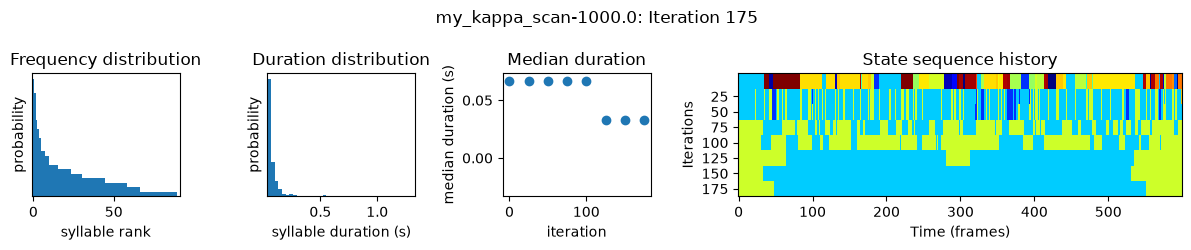

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  6.01it/s]

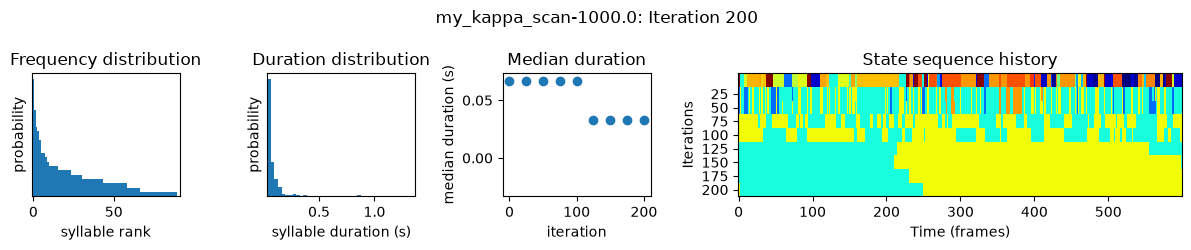

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  6.03it/s]

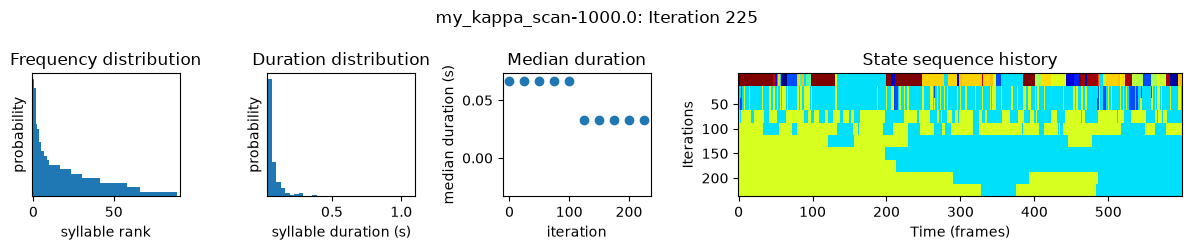

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  6.00it/s]

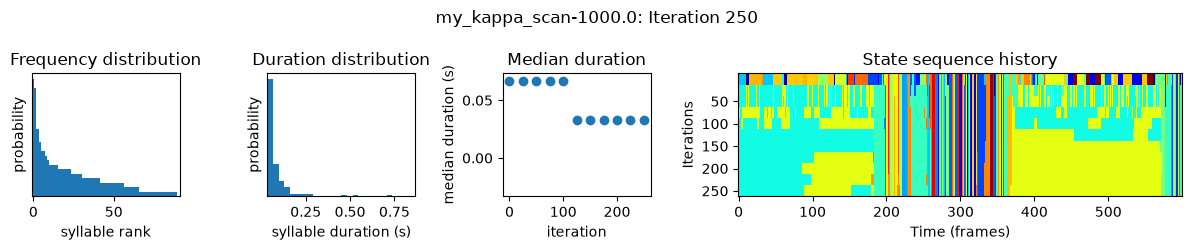

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.31it/s]


Fitting model with kappa=10000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.20it/s]

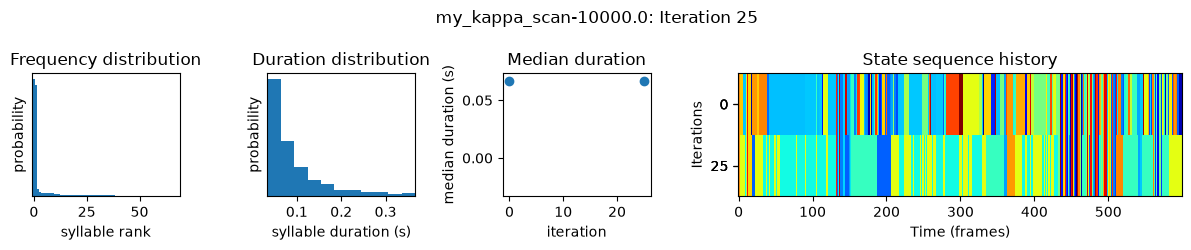

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.50it/s]

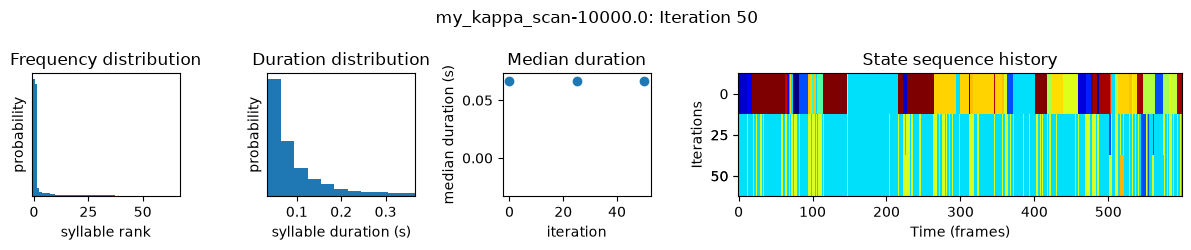

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.45it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.99it/s]

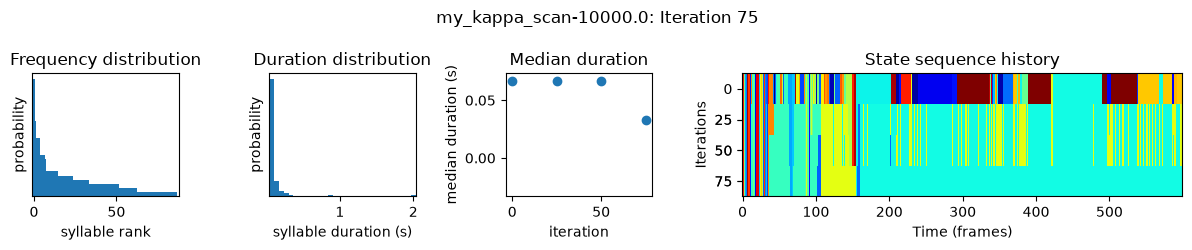

 25%|████████▍                         | 50/201 [00:08<00:25,  5.96it/s]

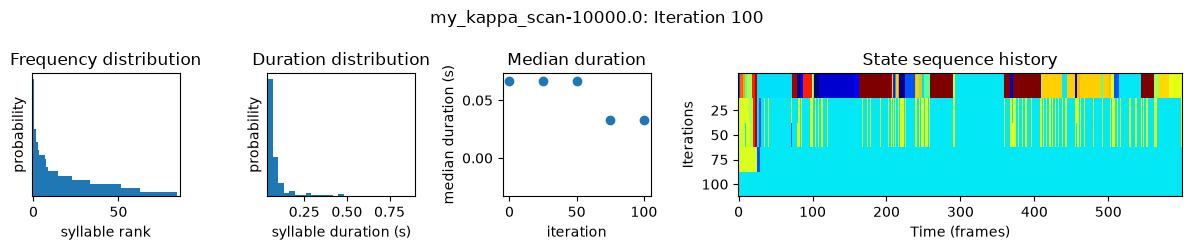

 37%|████████████▋                     | 75/201 [00:13<00:21,  5.93it/s]

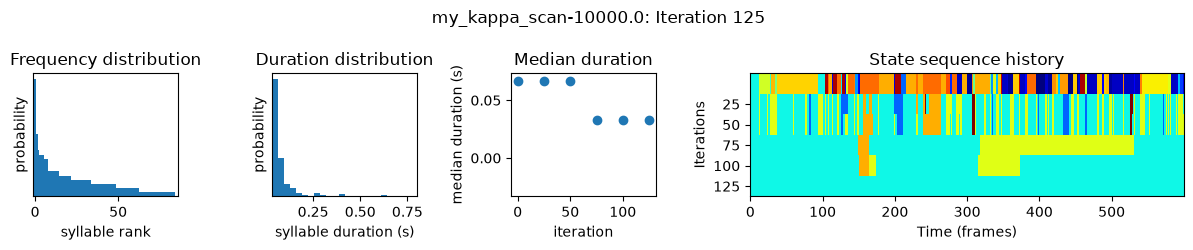

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.06it/s]

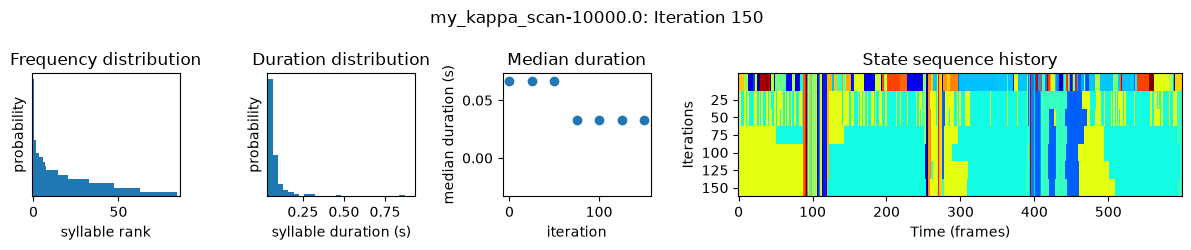

 62%|████████████████████▌            | 125/201 [00:22<00:12,  5.86it/s]

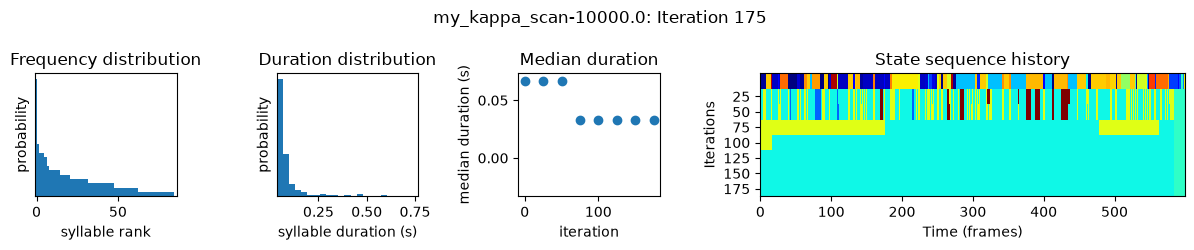

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  6.03it/s]

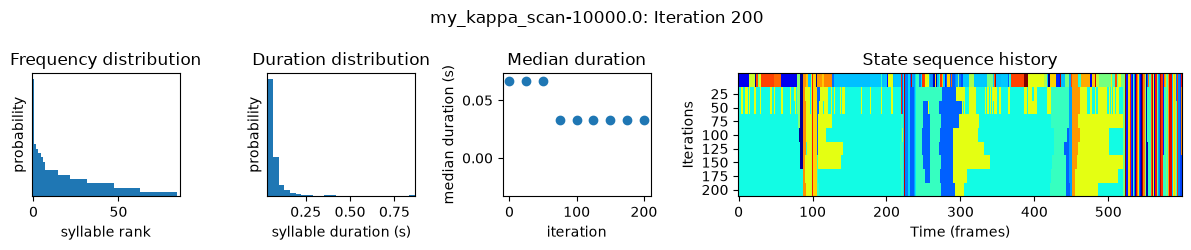

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.99it/s]

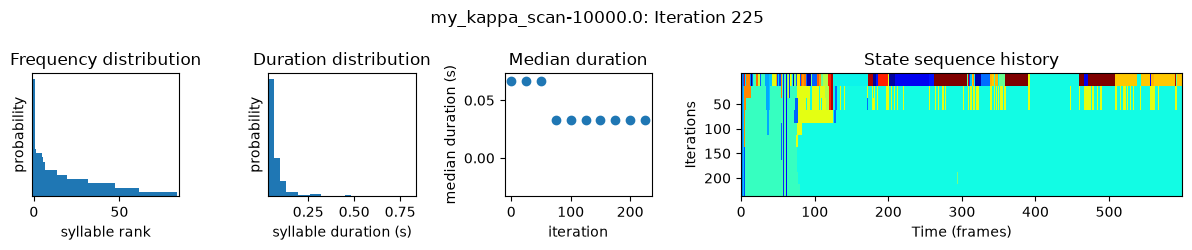

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  6.00it/s]

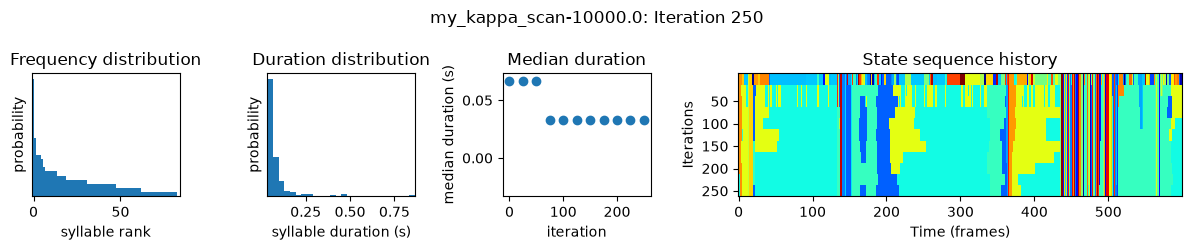

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.32it/s]


Fitting model with kappa=100000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-100000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.35it/s]

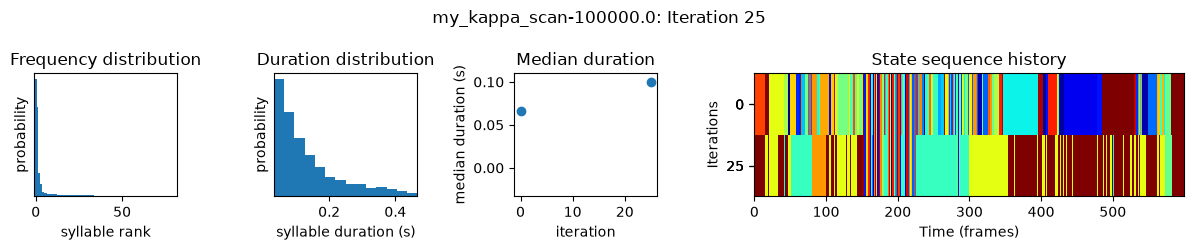

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.58it/s]

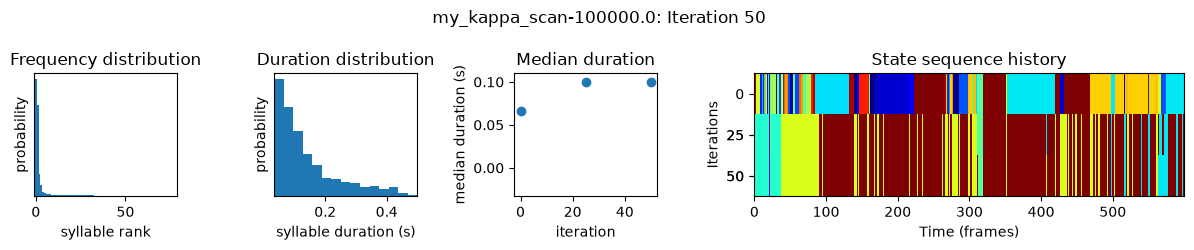

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.61it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-100000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.87it/s]

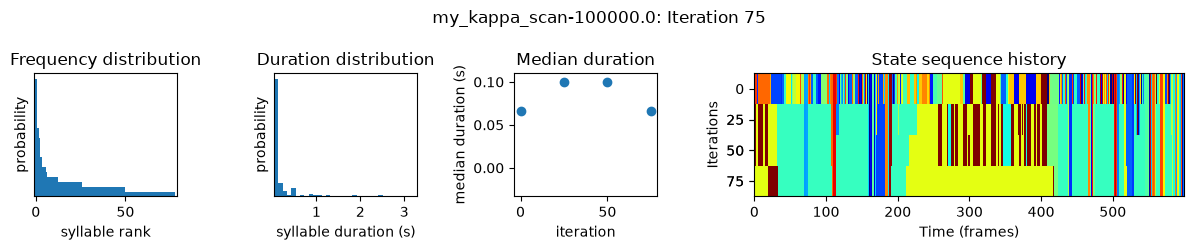

 25%|████████▍                         | 50/201 [00:09<00:26,  5.73it/s]

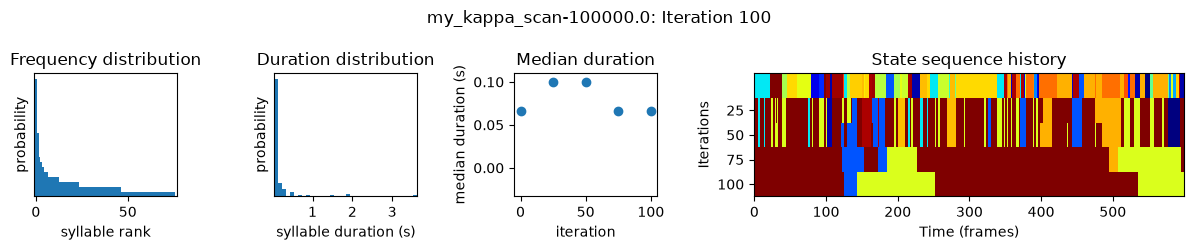

 37%|████████████▋                     | 75/201 [00:13<00:21,  5.76it/s]

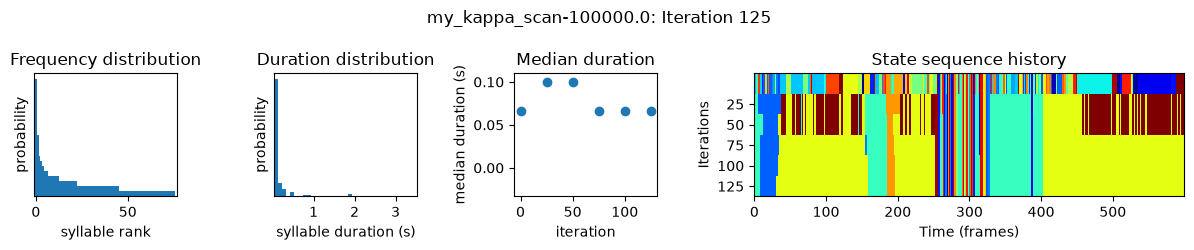

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.05it/s]

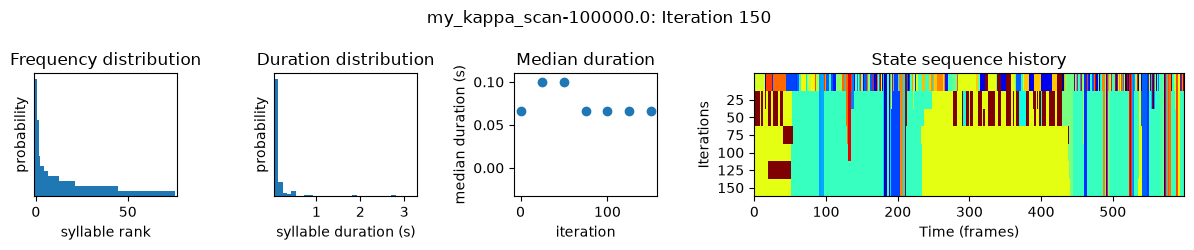

 62%|████████████████████▌            | 125/201 [00:23<00:13,  5.82it/s]

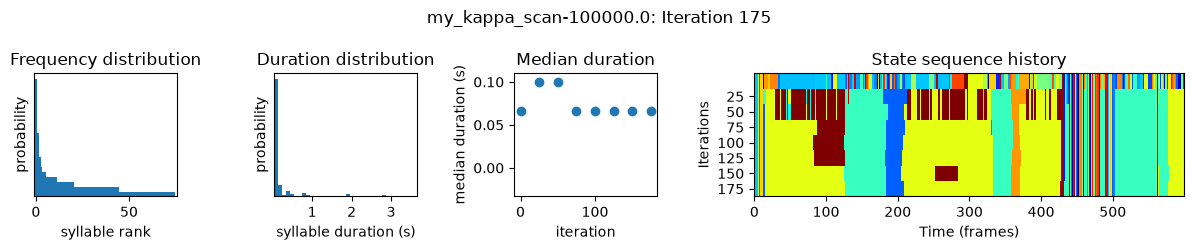

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  5.94it/s]

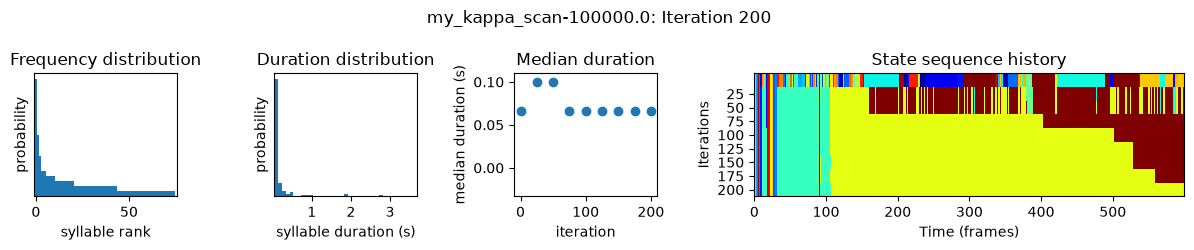

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.95it/s]

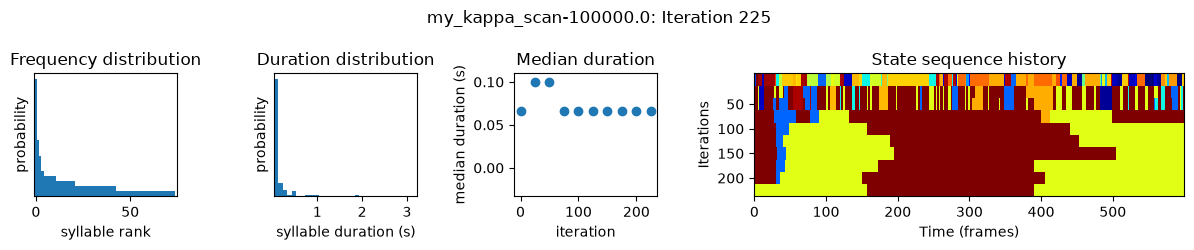

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  5.92it/s]

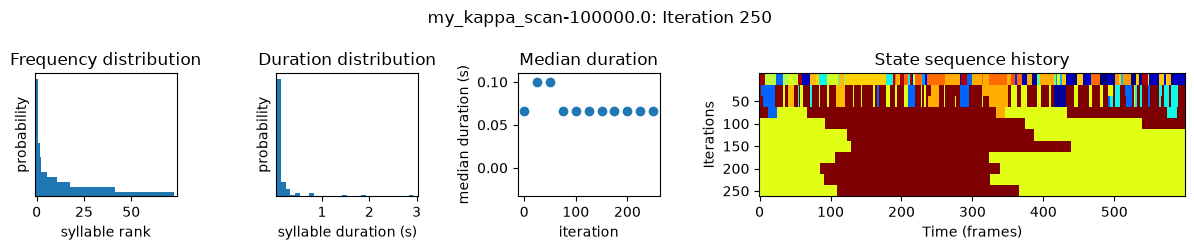

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.31it/s]


Fitting model with kappa=1000000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.30it/s]

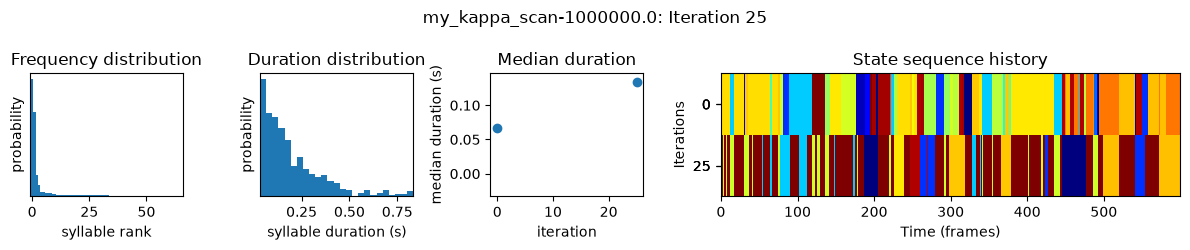

 98%|██████████████████████████████████▎| 50/51 [00:02<00:00, 19.42it/s]

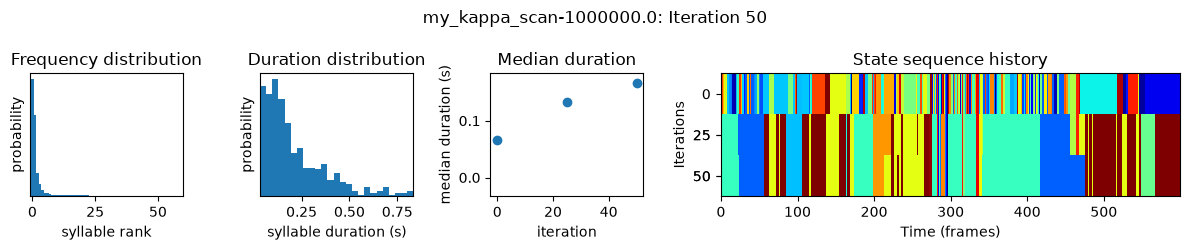

100%|███████████████████████████████████| 51/51 [00:03<00:00, 13.58it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-1000000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.97it/s]

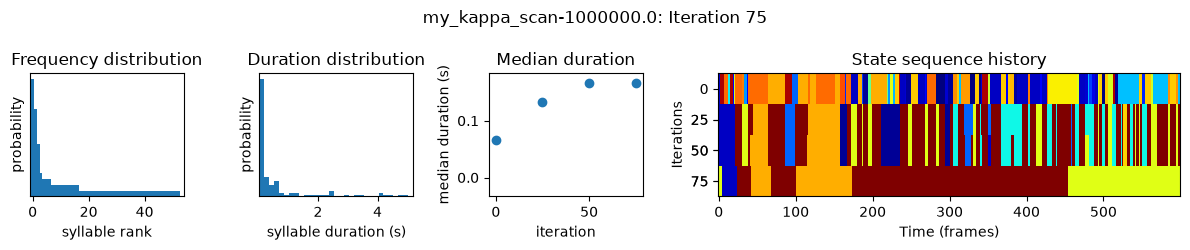

 25%|████████▍                         | 50/201 [00:08<00:25,  5.82it/s]

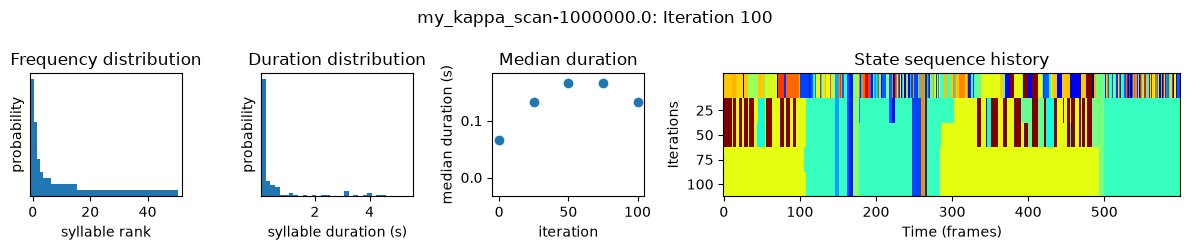

 37%|████████████▋                     | 75/201 [00:13<00:21,  5.93it/s]

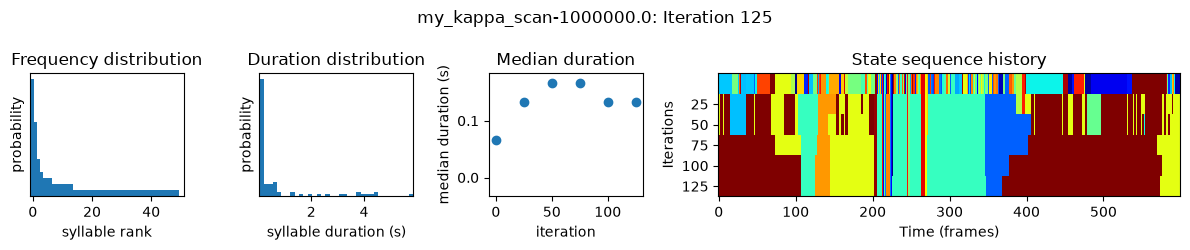

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.06it/s]

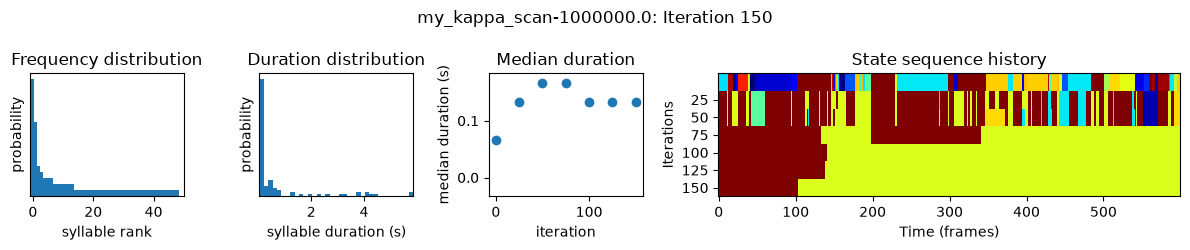

 62%|████████████████████▌            | 125/201 [00:23<00:13,  5.82it/s]

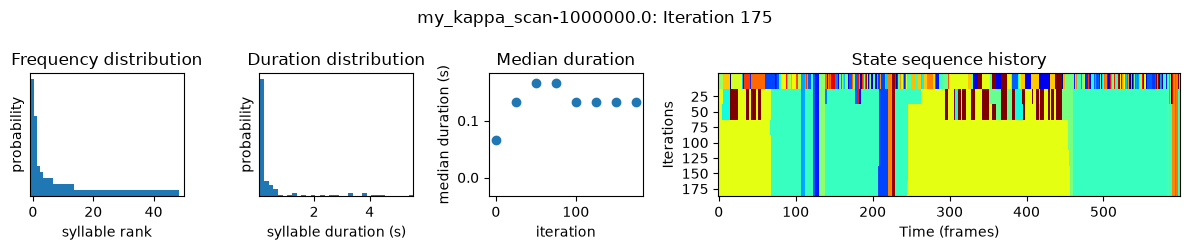

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  5.82it/s]

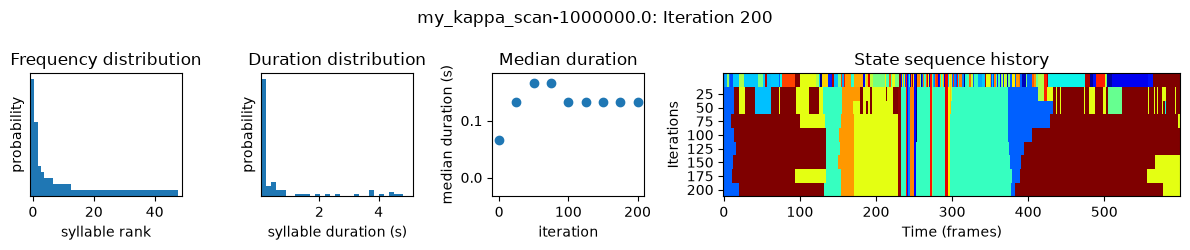

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.86it/s]

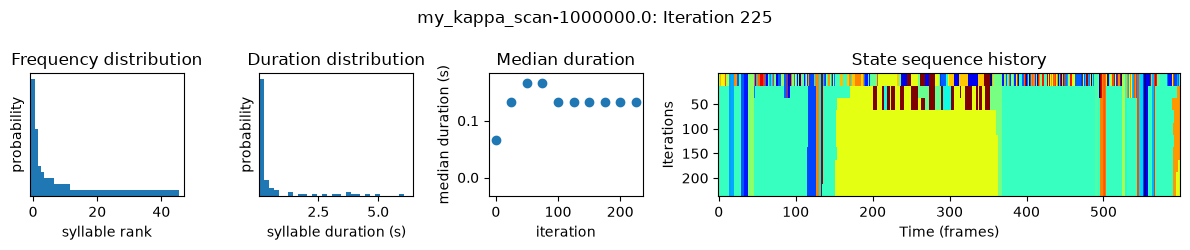

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  5.82it/s]

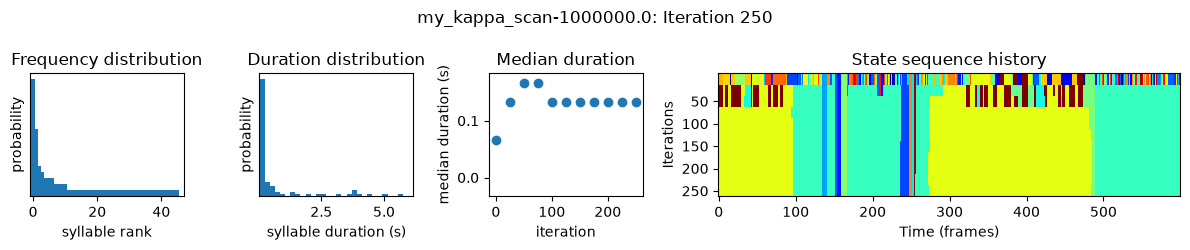

100%|█████████████████████████████████| 201/201 [00:37<00:00,  5.30it/s]


Fitting model with kappa=10000000.0
Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000000.0


 49%|█████████████████▏                 | 25/51 [00:01<00:01, 20.45it/s]

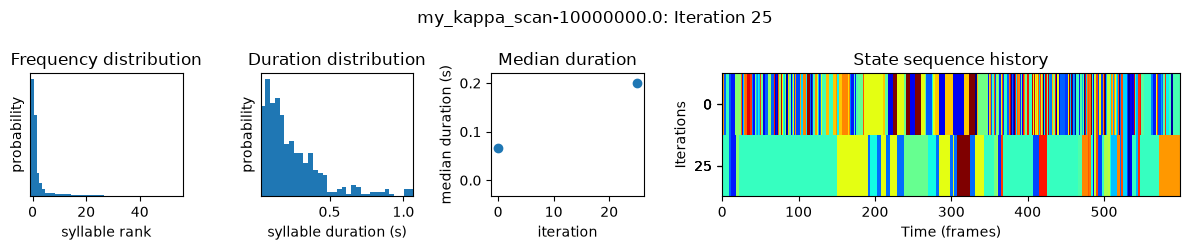

 96%|█████████████████████████████████▋ | 49/51 [00:02<00:00, 19.08it/s]

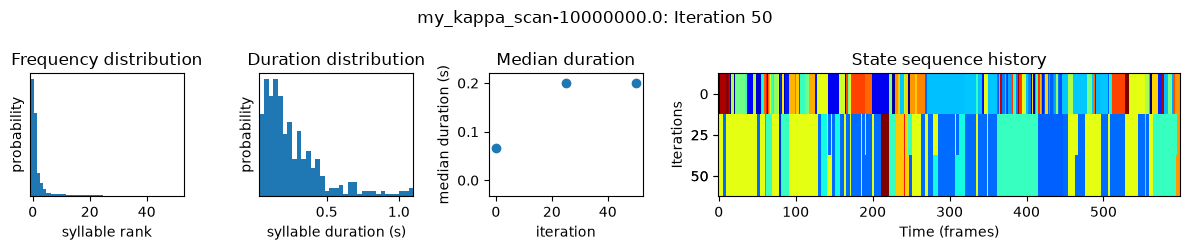

100%|███████████████████████████████████| 51/51 [00:03<00:00, 15.02it/s]


Outputs will be saved to /Volumes/groups/tanaka/People/current/jiwang/
projects/image_analysis/Deniz_video_sleap/sleap_test/kpms_test/my_kapp
a_scan-10000000.0


 12%|████▏                             | 25/201 [00:04<00:29,  5.93it/s]

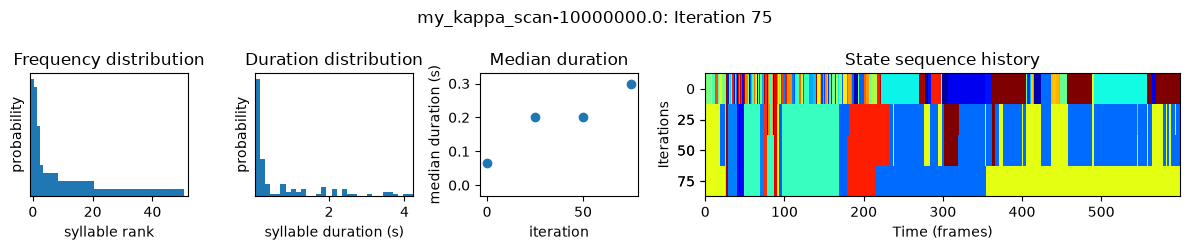

 25%|████████▍                         | 50/201 [00:08<00:25,  5.98it/s]

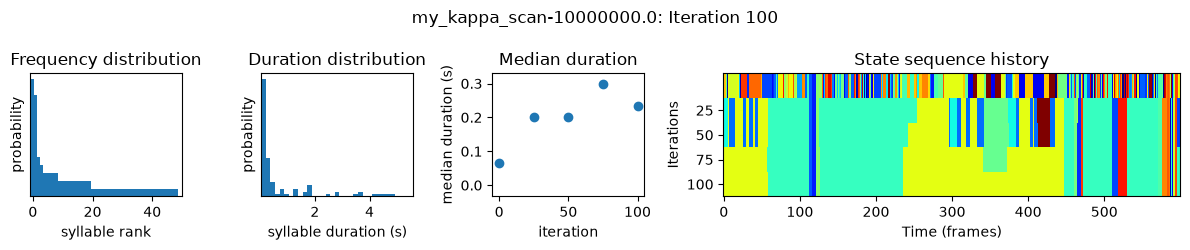

 37%|████████████▋                     | 75/201 [00:13<00:20,  6.02it/s]

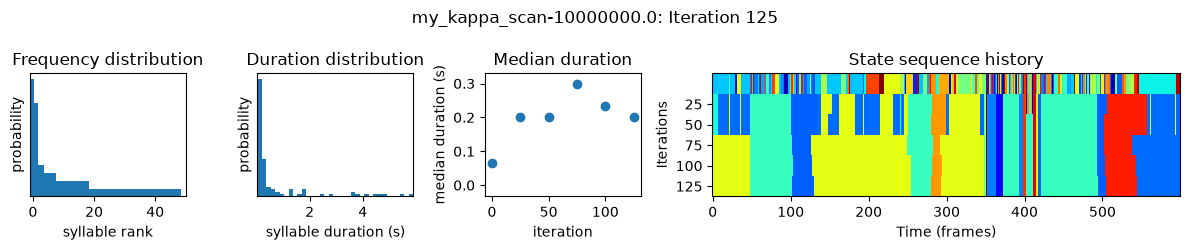

 50%|████████████████▍                | 100/201 [00:18<00:16,  6.14it/s]

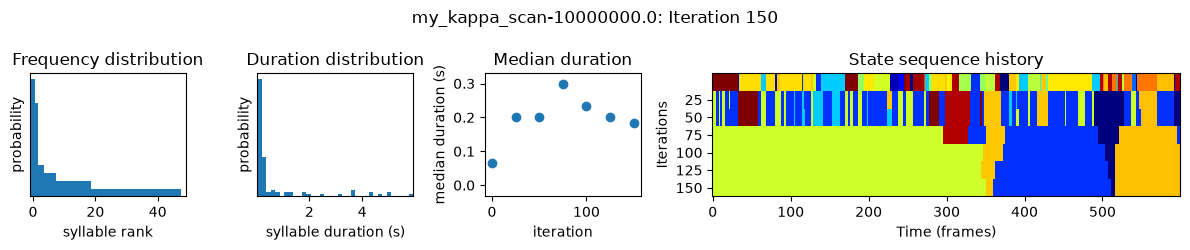

 62%|████████████████████▌            | 125/201 [00:22<00:12,  5.93it/s]

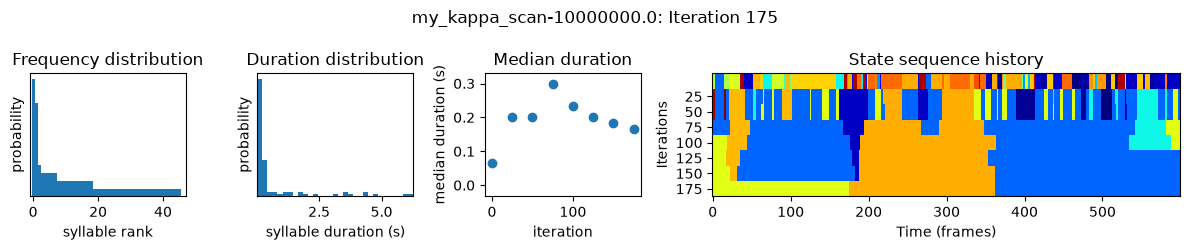

 75%|████████████████████████▋        | 150/201 [00:27<00:08,  6.01it/s]

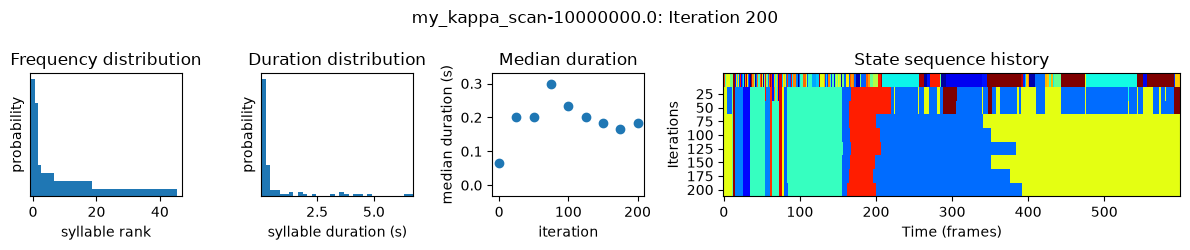

 87%|████████████████████████████▋    | 175/201 [00:32<00:04,  5.99it/s]

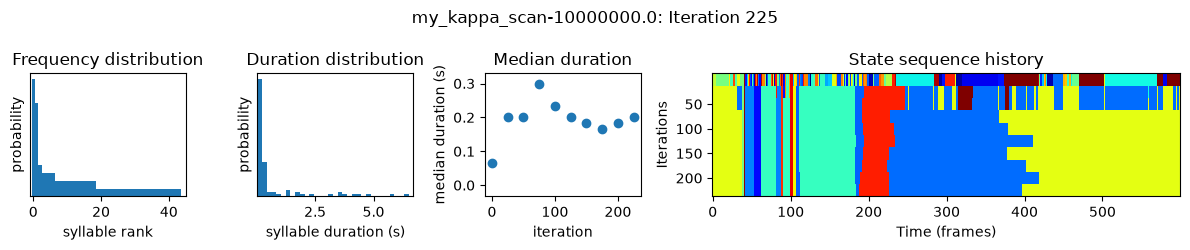

100%|████████████████████████████████▊| 200/201 [00:37<00:00,  5.96it/s]

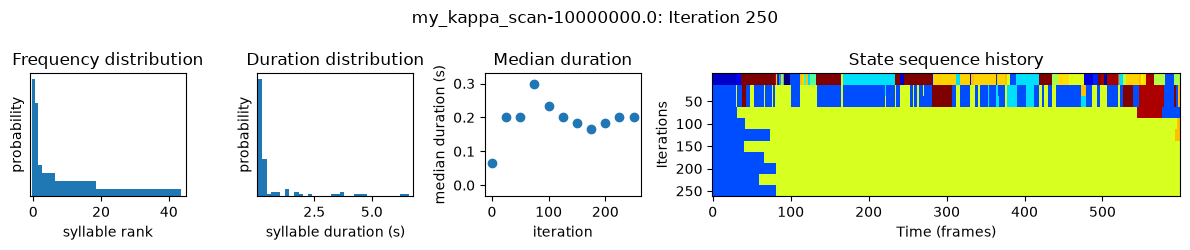

Loading checkpoints: 100%|█████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00,  5.13it/s]


(<Figure size 800x250 with 2 Axes>, array([1., 1., 2., 4., 6.]))

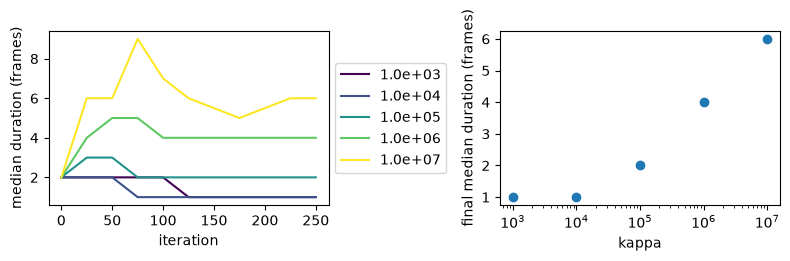

In [129]:
## Automatic kappa scan
import numpy as np

kappas = np.logspace(3,7,5)
decrease_kappa_factor = 10
num_ar_iters = 50
num_full_iters = 200

prefix = 'my_kappa_scan'

for kappa in kappas:
    print(f"Fitting model with kappa={kappa}")
    model_name = f'{prefix}-{kappa}'
    model = kpms.init_model(data, metadata=metadata, pca=pca, **config())

    # stage 1: fit the model with AR only
    model = kpms.update_hypparams(model, kappa=kappa)
    model = kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=True,
        num_iters=num_ar_iters,
        save_every_n_iters=25,
        **config()
    )[0];

    # stage 2: fit the full model
    model = kpms.update_hypparams(model, kappa=kappa/decrease_kappa_factor)
    kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=False,
        start_iter=num_ar_iters,
        num_iters=num_ar_iters + num_full_iters,
        save_every_n_iters=25,
        **config()
    );

kpms.plot_kappa_scan(kappas, project_dir, prefix)
